In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sys
sys.path.append('src')
import mineralML as mm
import pandas as pd
pd.set_option('display.max_columns', None)

%matplotlib inline
%config InlineBackend.figure_format = 'retina'
plt.rcParams.update({
    'xtick.major.size': 4,
    'ytick.major.size': 4,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'pdf.fonttype': 42,
    'font.family': 'Avenir',
    'font.size': 20,
    'xtick.direction': 'in',  # Set x-tick direction to 'in'
    'ytick.direction': 'in',  # Set y-tick direction to 'in'
    'xtick.major.size': 5,    # Set x-tick length
    'ytick.major.size': 5,    # Set y-tick length
    'xtick.major.pad': 6.5,   # Set x-tick padding
    'ytick.major.pad': 6.5    # Set y-tick padding
})


In [52]:
mm.load_minclass_nn()


(['Amphibole',
  'Apatite',
  'Biotite',
  'Chlorite',
  'Epidote',
  'Feldspar',
  'Garnet',
  'Glass',
  'Kalsilite',
  'Leucite',
  'Melilite',
  'Muscovite',
  'Nepheline',
  'Olivine',
  'Pyroxene',
  'Rhombohedral_Oxides',
  'Rutile',
  'Serpentine',
  'Spinel_Group',
  'Titanite',
  'Tourmaline'],
 {0: 'Amphibole',
  1: 'Apatite',
  2: 'Biotite',
  3: 'Chlorite',
  4: 'Epidote',
  5: 'Feldspar',
  6: 'Garnet',
  7: 'Glass',
  8: 'Kalsilite',
  9: 'Leucite',
  10: 'Melilite',
  11: 'Muscovite',
  12: 'Nepheline',
  13: 'Olivine',
  14: 'Pyroxene',
  15: 'Rhombohedral_Oxides',
  16: 'Rutile',
  17: 'Serpentine',
  18: 'Spinel_Group',
  19: 'Titanite',
  20: 'Tourmaline'})

In [47]:
df=pd.read_csv('Validation_Data/GEOROC_validationdata_Fe_2025.csv')
df.head()

,Unnamed: 0,CITATION,SAMPLE NAME,Mineral,SiO2,TiO2,Al2O3,Cr2O3,FeOt,MnO,MgO,NiO,CaO,Na2O,K2O,P2O5,ZrO2
0,26,[127] WRIGHT T. L. (1984),samp. RHSL-15,Amphibole,41.4,2.86,14.80,NaN,12.13,0.16,13.79,NaN,10.90,3.05,0.81,0.08,NaN
1,36,[241] CLAGUE D. A. (1991),samp. RM-PW-1,Amphibole,45.7,0.65,8.71,1.57,3.79,0.05,19.70,NaN,12.50,3.54,0.57,NaN,NaN
2,37,[241] CLAGUE D. A. (1991),samp. 68WAA-1,Amphibole,43.0,3.17,12.40,1.70,5.22,0.08,16.60,NaN,11.80,3.13,0.87,NaN,NaN
3,38,[241] CLAGUE D. A. (1991),samp. 68WAA-1,Amphibole,42.0,4.88,11.60,1.68,5.45,0.05,15.80,NaN,12.00,3.12,0.87,NaN,NaN
4,39,[241] CLAGUE D. A. (1991),samp. 87WAA-5,Amphibole,36.6,0.02,22.80,0.01,6.25,0.04,21.40,NaN,0.54,4.92,1.67,NaN,NaN


In [3]:
min_df = mm.prep_df_nn(df)
min_df_pred, min_probability_matrix = mm.predict_class_prob_nnwr(min_df)
min_df_pred['Citation']=df['CITATION']
min_df_pred['SAMPLE NAME']=df['SAMPLE NAME']

/var/folders/k_/fnnxsv2n52qb5r1hq85f3p2c0000gn/T/ipykernel_16125/753259856.py:1: UserWarning: Some non-numeric values were found in the oxides columns and have been coerced to NaN.
  min_df = mm.prep_df_nn(df)
/Users/sarahshi/Documents/GitHub/mineralML/src/mineralML/hybrid.py:1818: RuntimeWarning: invalid value encountered in sqrt
  std_matrix = np.sqrt(probs_var.detach().cpu().numpy())


## Ones that have the most things wrong

In [4]:
strings = min_df_pred.loc[
    min_df_pred["Predict_Mineral"].map(lambda x: isinstance(x, str)),
    "Predict_Mineral"
].unique()

strings

array(['Amphibole', 'Tourmaline', 'Glass', 'Clinopyroxene', 'Na-Pyroxene',
       'Biotite', 'Orthopyroxene', 'Chlorite', 'Serpentine', 'Olivine',
       'Garnet', 'Plagioclase', 'Nepheline', 'Titanite', 'Apatite',
       'Feldspar_Miscibility_Gap', 'Melilite', 'Epidote', 'Carbonate',
       'Muscovite', 'Leucite', 'SiO2_Polymorph', 'Alkali_Feldspar',
       'Rhombohedral_Oxides', 'Spinel_Group', 'Rutile', 'Kalsilite',
       'Zircon'], dtype=object)

In [5]:
df_Yam=min_df_pred.loc[min_df_pred['Citation']=='[26317] YAMASAKI T. (2022)']
df_Yam.to_clipboard(excel=True)

In [6]:
df_Yam_doesntmatch=df_Yam[(df_Yam['Mineral']=='Amphibole' )& (df_Yam['Predict_Mineral']!='Amphibole')]
df_Yam_doesmatch=df_Yam[(df_Yam['Mineral']=='Amphibole' )& (df_Yam['Predict_Mineral']=='Amphibole')]

len(df_Yam_doesntmatch)

64

In [7]:
df_Yam_doesntmatch['Predict_Mineral'].value_counts()

Predict_Mineral
Biotite        35
Plagioclase    29
Name: count, dtype: int64

In [8]:
df_Yam_doesntmatch[df_Yam_doesntmatch.Predict_Mineral=='Plagioclase'].head()

,SiO2,TiO2,Al2O3,FeOt,MnO,MgO,CaO,Na2O,K2O,Cr2O3,P2O5,ZrO2,Mineral,Predict_Mineral,Submineral,Predict_Probability,Predict_Probability_Sigma,Second_Predict_Mineral,Second_Predict_Probability,Citation,SAMPLE NAME
54450,48.06,0.05,32.47,0.03,0.00,0.00,15.96,2.48,0.04,0.00,0.0,0.0,Amphibole,Plagioclase,Bytownite,0.997485,0.012273,Glass,0.001795,[26317] YAMASAKI T. (2022),samp. AK129
54451,49.57,0.00,31.99,0.08,0.04,0.00,15.11,2.96,0.03,0.00,0.0,0.0,Amphibole,Plagioclase,Bytownite,0.996601,0.022551,Muscovite,0.003097,[26317] YAMASAKI T. (2022),samp. AK129
54452,54.77,0.00,28.41,0.04,0.00,0.01,11.05,5.21,0.11,0.00,0.0,0.0,Amphibole,Plagioclase,Labradorite,0.990358,0.066838,Glass,0.009045,[26317] YAMASAKI T. (2022),samp. AK129
54453,55.85,0.00,27.51,0.02,0.00,0.02,9.50,5.97,0.30,0.00,0.0,0.0,Amphibole,Plagioclase,Andesine,0.989815,0.068450,Glass,0.010089,[26317] YAMASAKI T. (2022),samp. AK129
54454,47.16,0.01,33.25,0.02,0.02,0.01,16.89,2.02,0.01,0.01,0.0,0.0,Amphibole,Plagioclase,Bytownite,0.996747,0.019273,Glass,0.002590,[26317] YAMASAKI T. (2022),samp. AK130


In [49]:
df_Yam_doesmatch

,SiO2,TiO2,Al2O3,FeOt,MnO,MgO,CaO,Na2O,K2O,Cr2O3,P2O5,ZrO2,Mineral,Predict_Mineral,Submineral,Predict_Probability,Predict_Probability_Sigma,Second_Predict_Mineral,Second_Predict_Probability,Citation,SAMPLE NAME
54411,49.49,0.75,4.90,16.56,0.41,11.77,12.45,0.39,0.43,0.01,0.0,0.0,Amphibole,Amphibole,NaN,0.985601,0.030101,Glass,0.007312,[26317] YAMASAKI T. (2022),samp. AK045B
54412,50.04,0.46,4.64,16.78,0.55,12.33,11.65,0.53,0.33,0.02,0.0,0.0,Amphibole,Amphibole,NaN,0.993502,0.010737,Pyroxene,0.005414,[26317] YAMASAKI T. (2022),samp. AK045B
54413,48.31,0.85,6.19,17.16,0.41,11.21,12.16,0.69,0.61,0.00,0.0,0.0,Amphibole,Amphibole,NaN,0.989255,0.017906,Pyroxene,0.008074,[26317] YAMASAKI T. (2022),samp. AK045B
54414,42.91,2.51,10.74,19.66,0.50,8.11,11.37,1.13,0.84,0.00,0.0,0.0,Amphibole,Amphibole,NaN,0.982252,0.057587,Glass,0.014358,[26317] YAMASAKI T. (2022),samp. AK048A
54415,43.70,2.36,9.72,19.65,0.55,8.73,10.89,1.17,0.71,0.05,0.0,0.0,Amphibole,Amphibole,NaN,0.993142,0.011960,Glass,0.005785,[26317] YAMASAKI T. (2022),samp. AK048A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54548,50.59,0.25,2.18,29.94,0.95,11.11,2.23,0.25,0.06,0.00,0.0,0.0,Amphibole,Amphibole,NaN,0.972765,0.100589,Glass,0.016391,[26317] YAMASAKI T. (2022),samp. AK237A
54549,51.13,0.15,1.65,29.81,0.91,11.49,2.18,0.20,0.04,0.03,0.0,0.0,Amphibole,Amphibole,NaN,0.987312,0.027757,Pyroxene,0.008207,[26317] YAMASAKI T. (2022),samp. AK237A
54550,48.09,0.86,7.14,15.97,0.44,12.28,11.29,0.90,0.27,0.02,0.0,0.0,Amphibole,Amphibole,NaN,0.978832,0.068989,Glass,0.016333,[26317] YAMASAKI T. (2022),samp. AK247
54551,49.38,0.63,6.16,15.58,0.40,12.84,11.53,0.65,0.23,0.02,0.0,0.0,Amphibole,Amphibole,NaN,0.978603,0.063030,Glass,0.013890,[26317] YAMASAKI T. (2022),samp. AK247


In [51]:
# overlay = {"Biotite": df_Yam_doesntmatch[df_Yam_doesntmatch.Predict_Mineral=='Biotite'],
# "Plagioclase": df_Yam_doesntmatch[df_Yam_doesntmatch.Predict_Mineral=='Plagioclase'],
# }

df_Yam = pd.concat([df_Yam_doesmatch, df_Yam_doesntmatch])

fig = mm.plot_z2_overlay(df_Yam,
                   ref_kws={'alpha':0.5, 's': 10, 'linewidths':0.5, 'edgecolors':'grey'},
                   new_kws={'alpha':1.0, 's': 70, 'linewidths':1, 'edgecolors':'k'},
                   filename='latentspace_yamasaki.pdf'
)
# fig.tight_layout()
# fig.savefig('latentspace_yamasaki.pdf')

/Users/sarahshi/Documents/GitHub/mineralML/src/mineralML/hybrid.py:2182: UserWarning: You passed a edgecolor/edgecolors ('grey') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(Zr[mask, 0], Zr[mask, 1], color=color, **ref_kws)


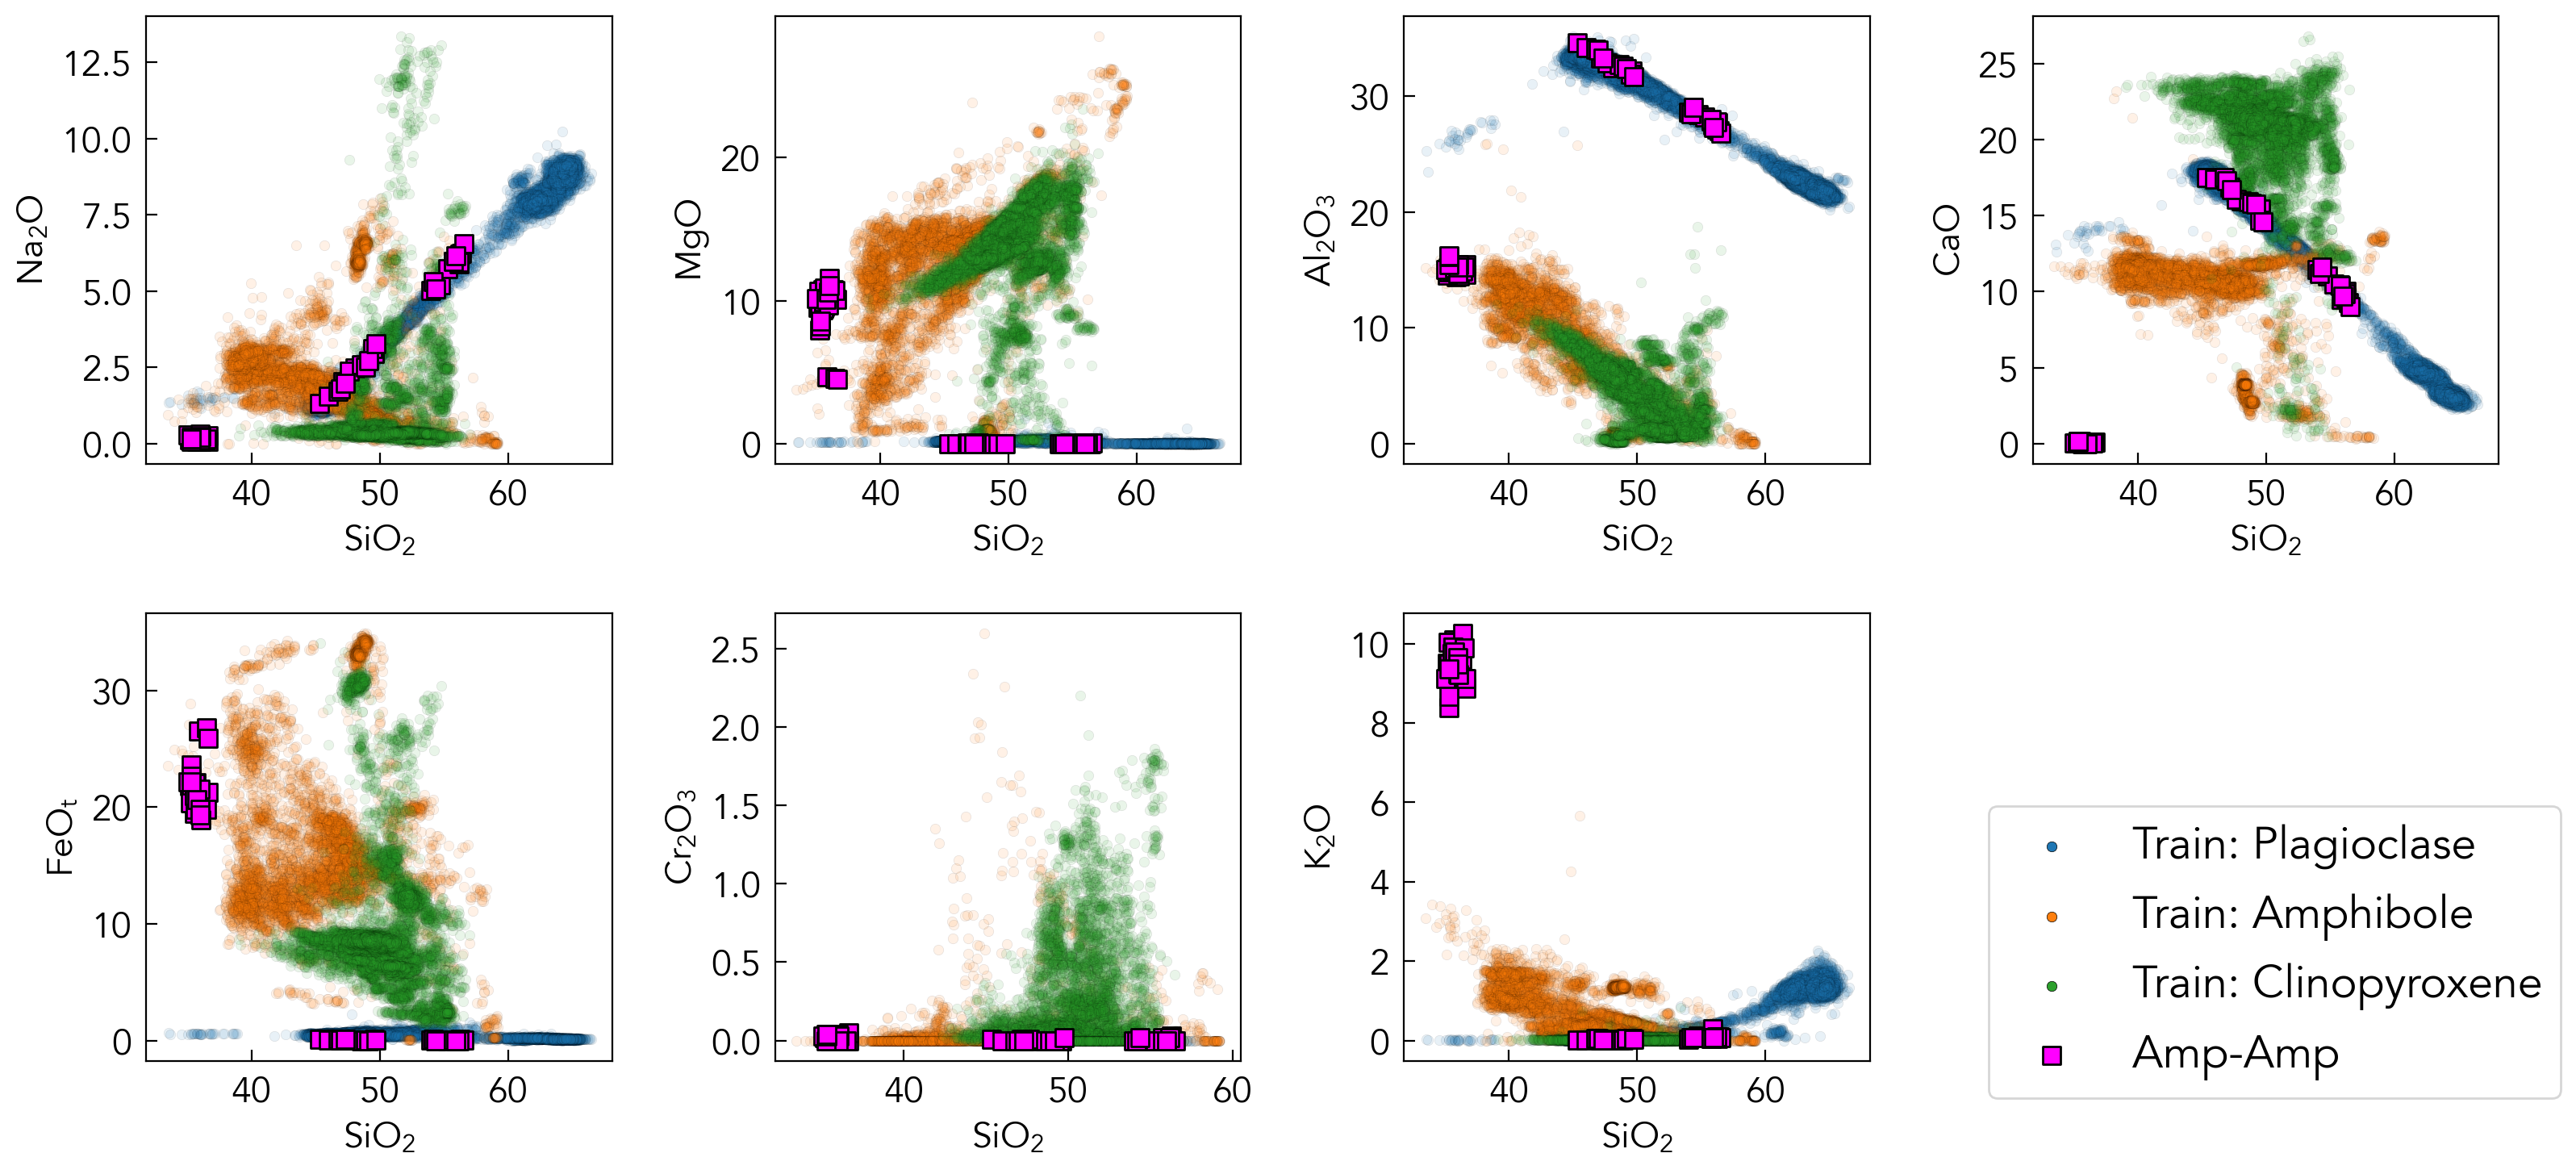

In [13]:
oxides=['Na2O', 'MgO', 'SiO2', 'Al2O3', 'CaO', 'FeOt', 'Cr2O3', 'K2O']
# Load your background training data
min_df = pd.read_csv("Training_Data/min_df_v4_natural.csv")

# Setup your specific overlay datasets 

# String key is the label that will appear in the legend!
overlays = {
    "Amp-Amp": df_Yam_doesntmatch,
    # "Clinopyroxene": df_Yam_doesntmatch.loc[df_Yam_doesntmatch['Predict_Mineral']=='Clinopyroxene'],
    #   "Plagioclase": df_Yam_doesntmatch.loc[df_Yam_doesntmatch['Predict_Mineral']=='Plagioclase'],

}

# Define what you want to plot
TRAIN_MINERALS = [ 'Plagioclase', 'Amphibole', 'Clinopyroxene']

# Call the function
mm.plot_harker(
    df_train=min_df,
    train_minerals=TRAIN_MINERALS,
    overlay_datasets=overlays,
    oxides=oxides,
    x_oxide="SiO2",
    train_mineral_col="Mineral"
    )


In [14]:

cm = pd.crosstab(
    df_Yam['Mineral'],
    df_Yam['Predict_Mineral']
)

cm_percent = cm.div(cm.sum(axis=1), axis=0) * 100

cm.round(2)

Predict_Mineral,Amphibole,Biotite,Plagioclase
Mineral,,,
Amphibole,78,35,29
Biotite,0,36,0
Feldspar,0,0,32


In [16]:
T_nat=pd.read_csv("Training_Data/min_df_v4_natural.csv")
T_syn=pd.read_csv("Training_Data/min_df_v4_synth.csv")
T_nat_Amp=T_nat[T_nat['Mineral']=='Amphibole']
T_syn_Amp=T_nat[T_syn['Mineral']=='Amphibole']
T_nat_Cpx=T_nat[T_nat['Mineral']=='Clinopyroxene']
T_syn_Cpx=T_nat[T_syn['Mineral']=='Clinopyroxene']

T_nat_Opx=T_nat[T_nat['Mineral']=='Orthopyroxene']
T_syn_Opx=T_nat[T_syn['Mineral']=='Orthopyroxene']

T_nat_Plag=T_nat[T_nat['Mineral']=='Plagioclase']

/var/folders/k_/fnnxsv2n52qb5r1hq85f3p2c0000gn/T/ipykernel_16125/1175963196.py:4: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  T_syn_Amp=T_nat[T_syn['Mineral']=='Amphibole']
/var/folders/k_/fnnxsv2n52qb5r1hq85f3p2c0000gn/T/ipykernel_16125/1175963196.py:6: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  T_syn_Cpx=T_nat[T_syn['Mineral']=='Clinopyroxene']
/var/folders/k_/fnnxsv2n52qb5r1hq85f3p2c0000gn/T/ipykernel_16125/1175963196.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  T_syn_Opx=T_nat[T_syn['Mineral']=='Orthopyroxene']


## Lets plot the ones that we agree are amphibole first

/var/folders/k_/fnnxsv2n52qb5r1hq85f3p2c0000gn/T/ipykernel_16125/3863362241.py:7: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  T_syn_Amp=T_nat[T_syn['Mineral']=='Amphibole']
/var/folders/k_/fnnxsv2n52qb5r1hq85f3p2c0000gn/T/ipykernel_16125/3863362241.py:9: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  T_syn_Cpx=T_nat[T_syn['Mineral']=='Clinopyroxene']
/var/folders/k_/fnnxsv2n52qb5r1hq85f3p2c0000gn/T/ipykernel_16125/3863362241.py:12: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  T_syn_Opx=T_nat[T_syn['Mineral']=='Orthopyroxene']


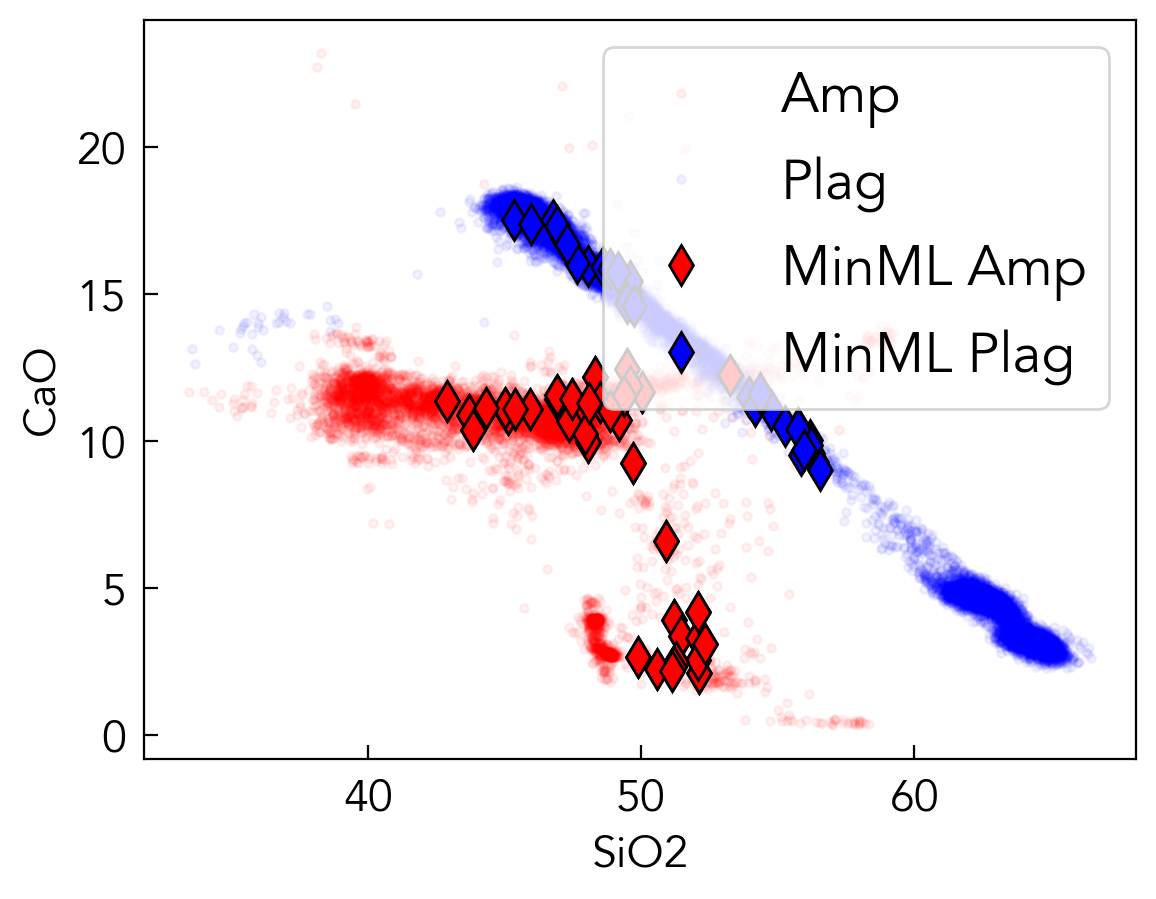

In [17]:
x='SiO2'
y='CaO'

T_nat=pd.read_csv("Training_Data/min_df_v4_natural.csv")
T_syn=pd.read_csv("Training_Data/min_df_v4_synth.csv")
T_nat_Amp=T_nat[T_nat['Mineral']=='Amphibole']
T_syn_Amp=T_nat[T_syn['Mineral']=='Amphibole']
T_nat_Cpx=T_nat[T_nat['Mineral']=='Clinopyroxene']
T_syn_Cpx=T_nat[T_syn['Mineral']=='Clinopyroxene']

T_nat_Opx=T_nat[T_nat['Mineral']=='Orthopyroxene']
T_syn_Opx=T_nat[T_syn['Mineral']=='Orthopyroxene']

T_nat_Plag=T_nat[T_nat['Mineral']=='Plagioclase']
plt.plot(T_nat_Amp[x], T_nat_Amp[y], '.r', alpha=0.05, label='Amp')
plt.plot(T_nat_Plag[x], T_nat_Plag[y], '.b', alpha=0.05, label='Plag')
IsAmp=(df_Yam['Predict_Mineral']=='Amphibole')& (df_Yam['Mineral']=='Amphibole')
IsPlag=(df_Yam['Predict_Mineral']=='Plagioclase')& (df_Yam['Mineral']=='Amphibole')
plt.plot(df_Yam[x].loc[IsAmp], df_Yam[y].loc[IsAmp], 'dk', mfc='red', ms=10, label='MinML Amp')
plt.plot(df_Yam[x].loc[IsPlag], df_Yam[y].loc[IsPlag], 'dk', mfc='blue', ms=10, label='MinML Plag')
plt.xlabel(x)
plt.ylabel(y)
plt.legend()

Alkali_Feldspar
Amphibole
Biotite
Carbonate
Chlorite
Clinopyroxene
Feldspar_Miscibility_Gap
Garnet
Glass
Muscovite
Na-Pyroxene
Nepheline
Olivine
Orthopyroxene
Plagioclase
Rhombohedral_Oxides
Rutile
Serpentine
SiO2_Polymorph
Spinel_Group
Tourmaline
Alkali_Feldspar
Amphibole
Biotite
Carbonate
Chlorite
Clinopyroxene
Feldspar_Miscibility_Gap
Garnet
Glass
Muscovite
Na-Pyroxene
Nepheline
Olivine
Orthopyroxene
Plagioclase
Rhombohedral_Oxides
Rutile
Serpentine
SiO2_Polymorph
Spinel_Group
Tourmaline
Alkali_Feldspar
Amphibole
Biotite
Carbonate
Chlorite
Clinopyroxene
Feldspar_Miscibility_Gap
Garnet
Glass
Muscovite
Na-Pyroxene
Nepheline
Olivine
Orthopyroxene
Plagioclase
Rhombohedral_Oxides
Rutile
Serpentine
SiO2_Polymorph
Spinel_Group
Tourmaline
Alkali_Feldspar
Amphibole
Biotite
Carbonate
Chlorite
Clinopyroxene
Feldspar_Miscibility_Gap
Garnet
Glass
Muscovite
Na-Pyroxene
Nepheline
Olivine
Orthopyroxene
Plagioclase
Rhombohedral_Oxides
Rutile
Serpentine
SiO2_Polymorph
Spinel_Group
Tourmaline
Alkali_F

/Users/sarahshi/anaconda3/envs/science/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8594 (\N{RIGHTWARDS ARROW}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)


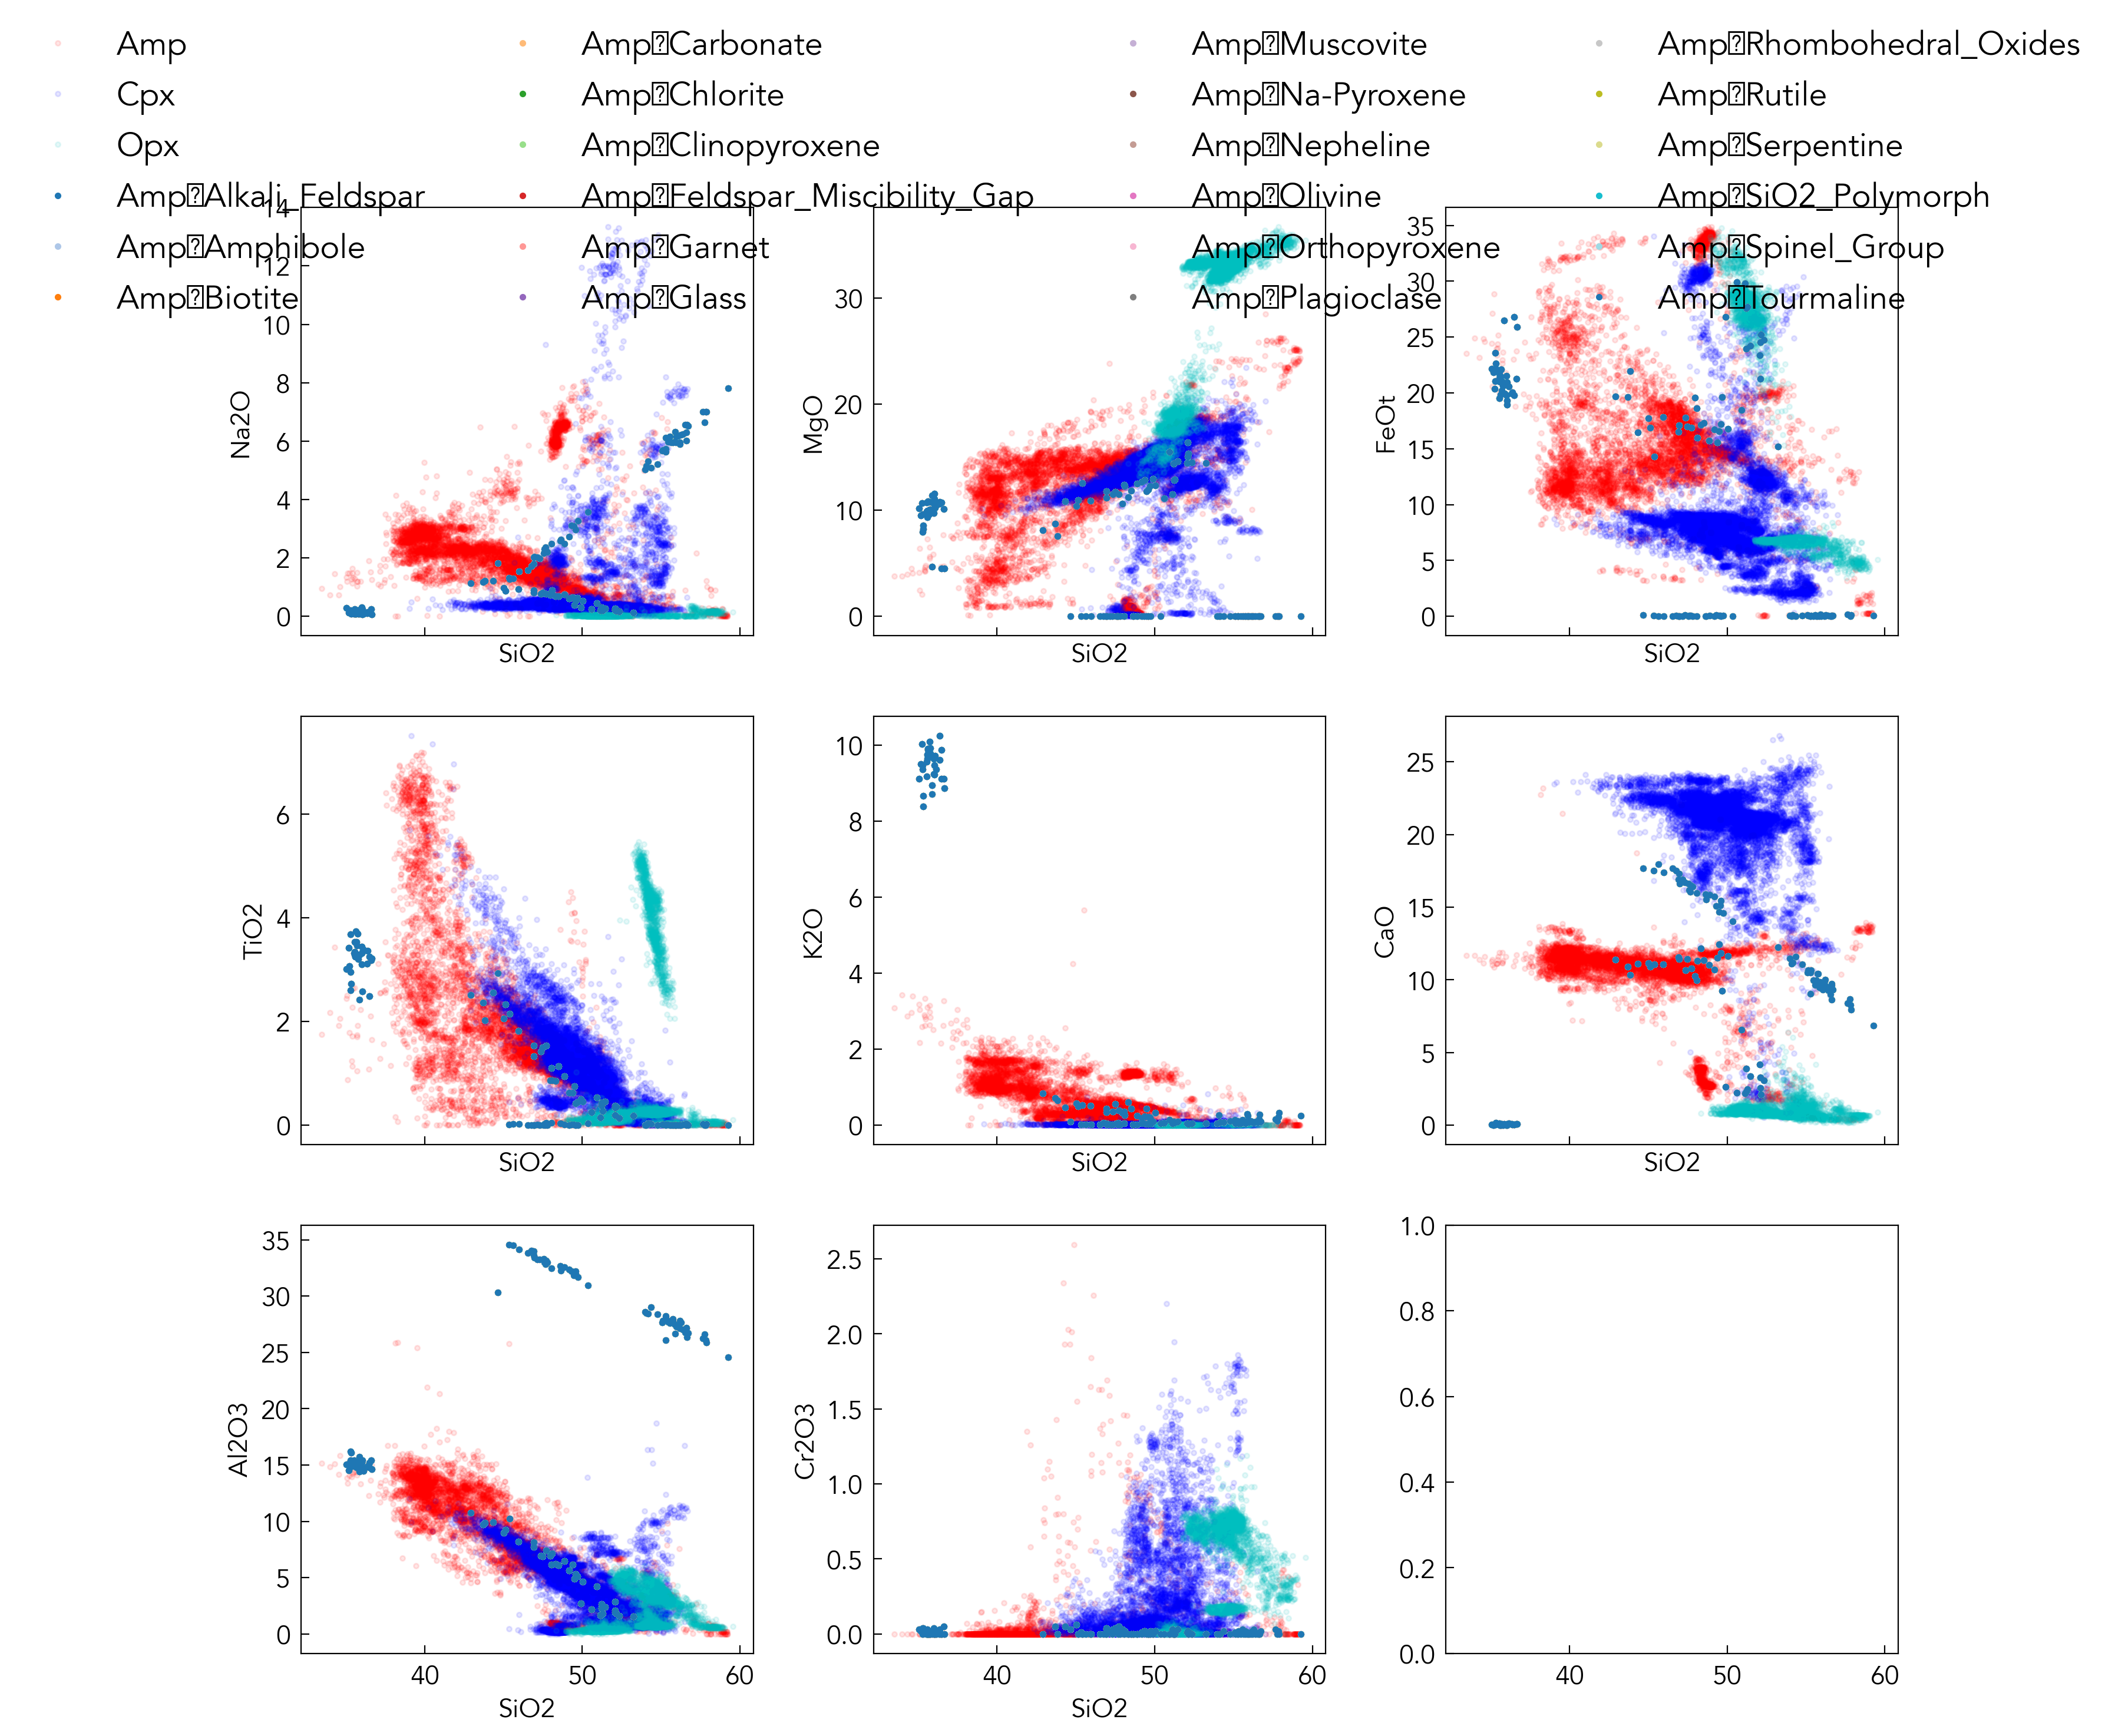

In [18]:
import matplotlib.pyplot as plt

x = 'SiO2'
ys = ['Na2O', 'MgO', 'FeOt', 'TiO2', 'K2O', 'CaO', 'Al2O3', 'Cr2O3']

fig, axes = plt.subplots(3, 3, figsize=(15, 15), sharex=True)
axes = axes.ravel()

mask_mis = (
    (min_df_pred['Mineral'] == 'Amphibole') &
    (min_df_pred['CaO'] < 5)
)

mis_df = min_df_pred.loc[mask_mis].copy()

# --- Auto color map for whatever predicted minerals exist ---
pred_classes = sorted(mis_df['Predict_Mineral'].dropna().unique())
cmap = plt.get_cmap('tab20')  # good for up to ~20 distinct classes
color_map = {cls: cmap(i % cmap.N) for i, cls in enumerate(pred_classes)}

for ax, y in zip(axes, ys):
    ax.plot(T_nat_Amp[x], T_nat_Amp[y], '.r', alpha=0.1, label='Amp')
    ax.plot(T_nat_Cpx[x], T_nat_Cpx[y], '.b', alpha=0.1, label='Cpx')
    ax.plot(T_nat_Opx[x], T_nat_Opx[y], '.c', alpha=0.1, label='Opx')



    # Misclassified amphiboles colored by Predict_Mineral
    for cls, grp in mis_df.groupby('Predict_Mineral'):
        print(cls)
        ax.plot(
            df_Yam[x], df_Yam[y],
            '.',
            color=color_map.get(cls, 'k'),
            markersize=6,
            label=f'Amp→{cls}'
        )

    ax.set_xlabel(x)
    ax.set_ylabel(y)

# --- Make ONE legend for the whole figure, with unique entries ---
handles, labels = axes[0].get_legend_handles_labels()
seen = set()
uniq_handles, uniq_labels = [], []
for h, lab in zip(handles, labels):
    if lab not in seen:
        uniq_handles.append(h)
        uniq_labels.append(lab)
        seen.add(lab)

fig.legend(uniq_handles, uniq_labels, loc='upper center', ncol=4, frameon=False)

plt.tight_layout(rect=[0, 0, 1, 0.9])
plt.show()

In [19]:
# Now, let's classify and plot up these amphiboles.
amp_class = mm.AmphiboleClassifier(df_S_Amp)
amp_comp_class = amp_class.classify()
fig, ax = amp_class.plot()

# Note the addition of the Submineral column providing a calcic amphibole classification.
display(amp_comp_class.head())

amp_class = mm.AmphiboleClassifier(T_nat_Amp)
amp_comp_class = amp_class.classify()
fig, ax = amp_class.plot()

# Note the addition of the Submineral column providing a calcic amphibole classification.
display(amp_comp_class.head())

NameError: name 'df_S_Amp' is not defined

In [41]:
df_TC_Px=pd.read_excel('Torres_Orozco.xlsx', sheet_name='3.Pyroxene Gps')
df_TC_Px_YW2=df_TC_Px.loc[df_TC_Px['Sample.1']=='YW2']
df_TC_Px_GP2=df_TC_Px.loc[df_TC_Px['Sample.1']=='GP2']
df_TC_Amp=pd.read_excel('Torres_Orozco.xlsx', sheet_name='4.Amph Gps')
df_TC_Amp_GP2=df_TC_Amp.loc[df_TC_Amp['Sample.1']=='GP2']
df_TC_Amp_YW2=df_TC_Amp.loc[df_TC_Amp['Sample.1']=='YW2']

In [42]:
df_TC_Px.columns

Index(['Sample', 'Sample.1', 'SiO2', 'TiO2', 'Al2O3', 'Cr2O3', 'Fe2O3', 'FeO',
       'MnO', 'NiO', 'CoO', 'ZnO', 'MgO', 'CaO', 'Na2O', 'Total', 'Comment',
       'En%', 'Wo%', 'Fs%'],
      dtype='object')

In [43]:
df_TC_Amp

,Sample,Sample.1,MineralGroup,SiO2,TiO2,Al2O3,Cr2O3,FeO,MnO,MgO,CaO,Na2O,K2O,F,Cl,Total,Comment,Unnamed: 17,H2O(calc),[PEL98(kbar)a,TEL98(oC)a],[TF06(oC)a,[PLC10(MPa)a],[TR10(oC)a,PR10(MPa)a,ACDCCkm)a,P1bRR12(MPa)a,P1cRR12(MPa)a,TRR12P1b(oC)a,TRR12P1c(oC)a,SiO2meltRR12(%)a,[TP16SiinHbl(oC)a,TP16Eq5(oC)a,Put16a_PHZ86(kbar)a,Put16b_PHZ86(kbar)a],[PM16(kbar)a],T2HB94_PHZ86(oC)a-p,T2HB94_PH87(oC)a-p,T2HB94_PJR89(oC)a-p,T2HB94_PS92(oC)a-p,T2HB94_PA97_PJR89(oC)a-p,T2HB94_PA97_PS92(oC)a-p],T2HB94_PP16a_PHZ86(oC)a-p,T2HB94_PP16b_PHZ86(oC)a-p,[T2HB94_P2AS95(oC)a-p,[T1P16(oC)l,T2P16(oC)a-l,T3P16(oC)a-l,T4P16(oC)a-l,T5P16(oC)a-l,T6P16(oC)a-l,SiO2(wt%)a-l],Unnamed: 52,H2OmeltR10(%)a,Unnamed: 54,H2O(wt%)a-l,Unnamed: 56,[QFM_P16(fO2)a,NNO_P16(fO2)a,HM_P16(fO2)a]
0,GP1(Ti-richMg-hastingsite),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,A4-1,NaN,NaN,42.6849,2.8168,11.4526,0.0000,12.4783,0.4838,13.7209,11.7514,2.4324,0.9111,0.2530,0.0901,98.9486,UIG7PGHbl4C-RLine001,A4-1,1.901001,3.042127,827.289656,907.951687,448.092241,959.141064,320.900091,8.664302,331.623666,425.264528,985.346883,991.417909,65.456585,943.176396,949.511238,5.018865,4.879396,5.011631,1085.835883,1086.897797,1082.594175,1086.916794,1084.552933,1084.588623,1082.878373,1082.476459,1041.678975,838.899394,885.570016,837.589786,908.396181,935.953319,933.744296,61.168451,NaN,4.724630,6.058461,3.239130,NaN,-12.118132,-11.319156,-6.528381
2,A4-3,NaN,NaN,42.6311,3.0708,10.7853,0.0251,12.1354,0.4439,14.1551,11.6347,2.4472,0.8598,0.2000,0.0906,98.3745,UIG7PGHbl4C-RLine003,A4-3,1.916123,1.851613,821.164741,937.092922,305.726113,953.050041,275.089413,7.427414,296.313232,395.907701,994.169179,1001.242318,65.61541,939.772734,953.702110,4.492176,4.168990,4.568555,1080.868275,1081.271888,1079.486066,1081.405010,1080.483283,1080.504378,1079.514842,1079.085255,1061.361318,839.921827,883.314484,844.733677,919.304290,939.662314,944.440150,61.755087,NaN,4.046813,5.328367,1.384179,NaN,-12.093842,-11.276375,-6.471841
3,A4-4,NaN,NaN,42.9129,2.8058,11.2179,0.0000,12.2057,0.4011,14.2625,11.7177,2.4207,0.8454,0.1640,0.0517,98.9247,UIG7PGHbl4C-RLine004,\nA4-4,1.959961,2.623672,822.494792,905.883271,398.051824,955.677321,298.983163,8.072545,311.5778,397.472019,977.714418,983.657654,65.733943,940.511873,949.405261,4.789376,4.560969,4.807545,1068.779951,1069.489869,1066.511860,1069.587223,1067.991273,1068.020196,1066.641087,1066.165131,1039.351525,838.899394,884.976693,839.497896,912.205212,935.344295,937.855643,61.596941,NaN,4.478518,5.858253,1.972425,NaN,-12.157297,-11.343394,-6.544636
4,A4-5,NaN,NaN,42.5511,2.8897,11.7007,0.0000,12.2783,0.4025,13.7666,11.7394,2.4543,0.8456,0.2067,0.0743,98.8055,UIG7PGHbl4C-RLine005,\nA4-5,1.926315,3.318524,834.659635,915.584372,479.171645,964.744474,340.626321,9.196911,344.094488,423.233991,980.335609,985.388697,64.441814,947.271962,955.740432,5.235026,5.192336,5.191526,1060.693561,1061.935466,1057.042975,1061.839770,1059.097038,1059.131726,1057.475034,1057.340516,1016.949704,839.921827,882.913596,841.486132,916.965802,941.542483,937.916705,60.199286,NaN,4.983702,6.072005,2.694625,NaN,-12.037252,-11.233121,-6.434540
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,A4-6,YW2,(Cr-Actinolite),52.7268,0.2155,1.0591,0.0027,7.1772,1.0252,15.6574,22.1416,0.4240,0.0067,0.0000,0.0117,100.4453,UIG7PWHbl4C-RLine006,\nA4-6,2.109698,----,327.505401,477.494073,45.020334,641.366179,25.335202,0.684050,----,----,----,----,----,725.616943,742.718490,0.039258,0.338035,0.593850,804.010915,805.641582,803.302058,802.089915,799.121834,798.962476,797.176433,796.510687,804.601720,876.136075,783.741044,773.913479

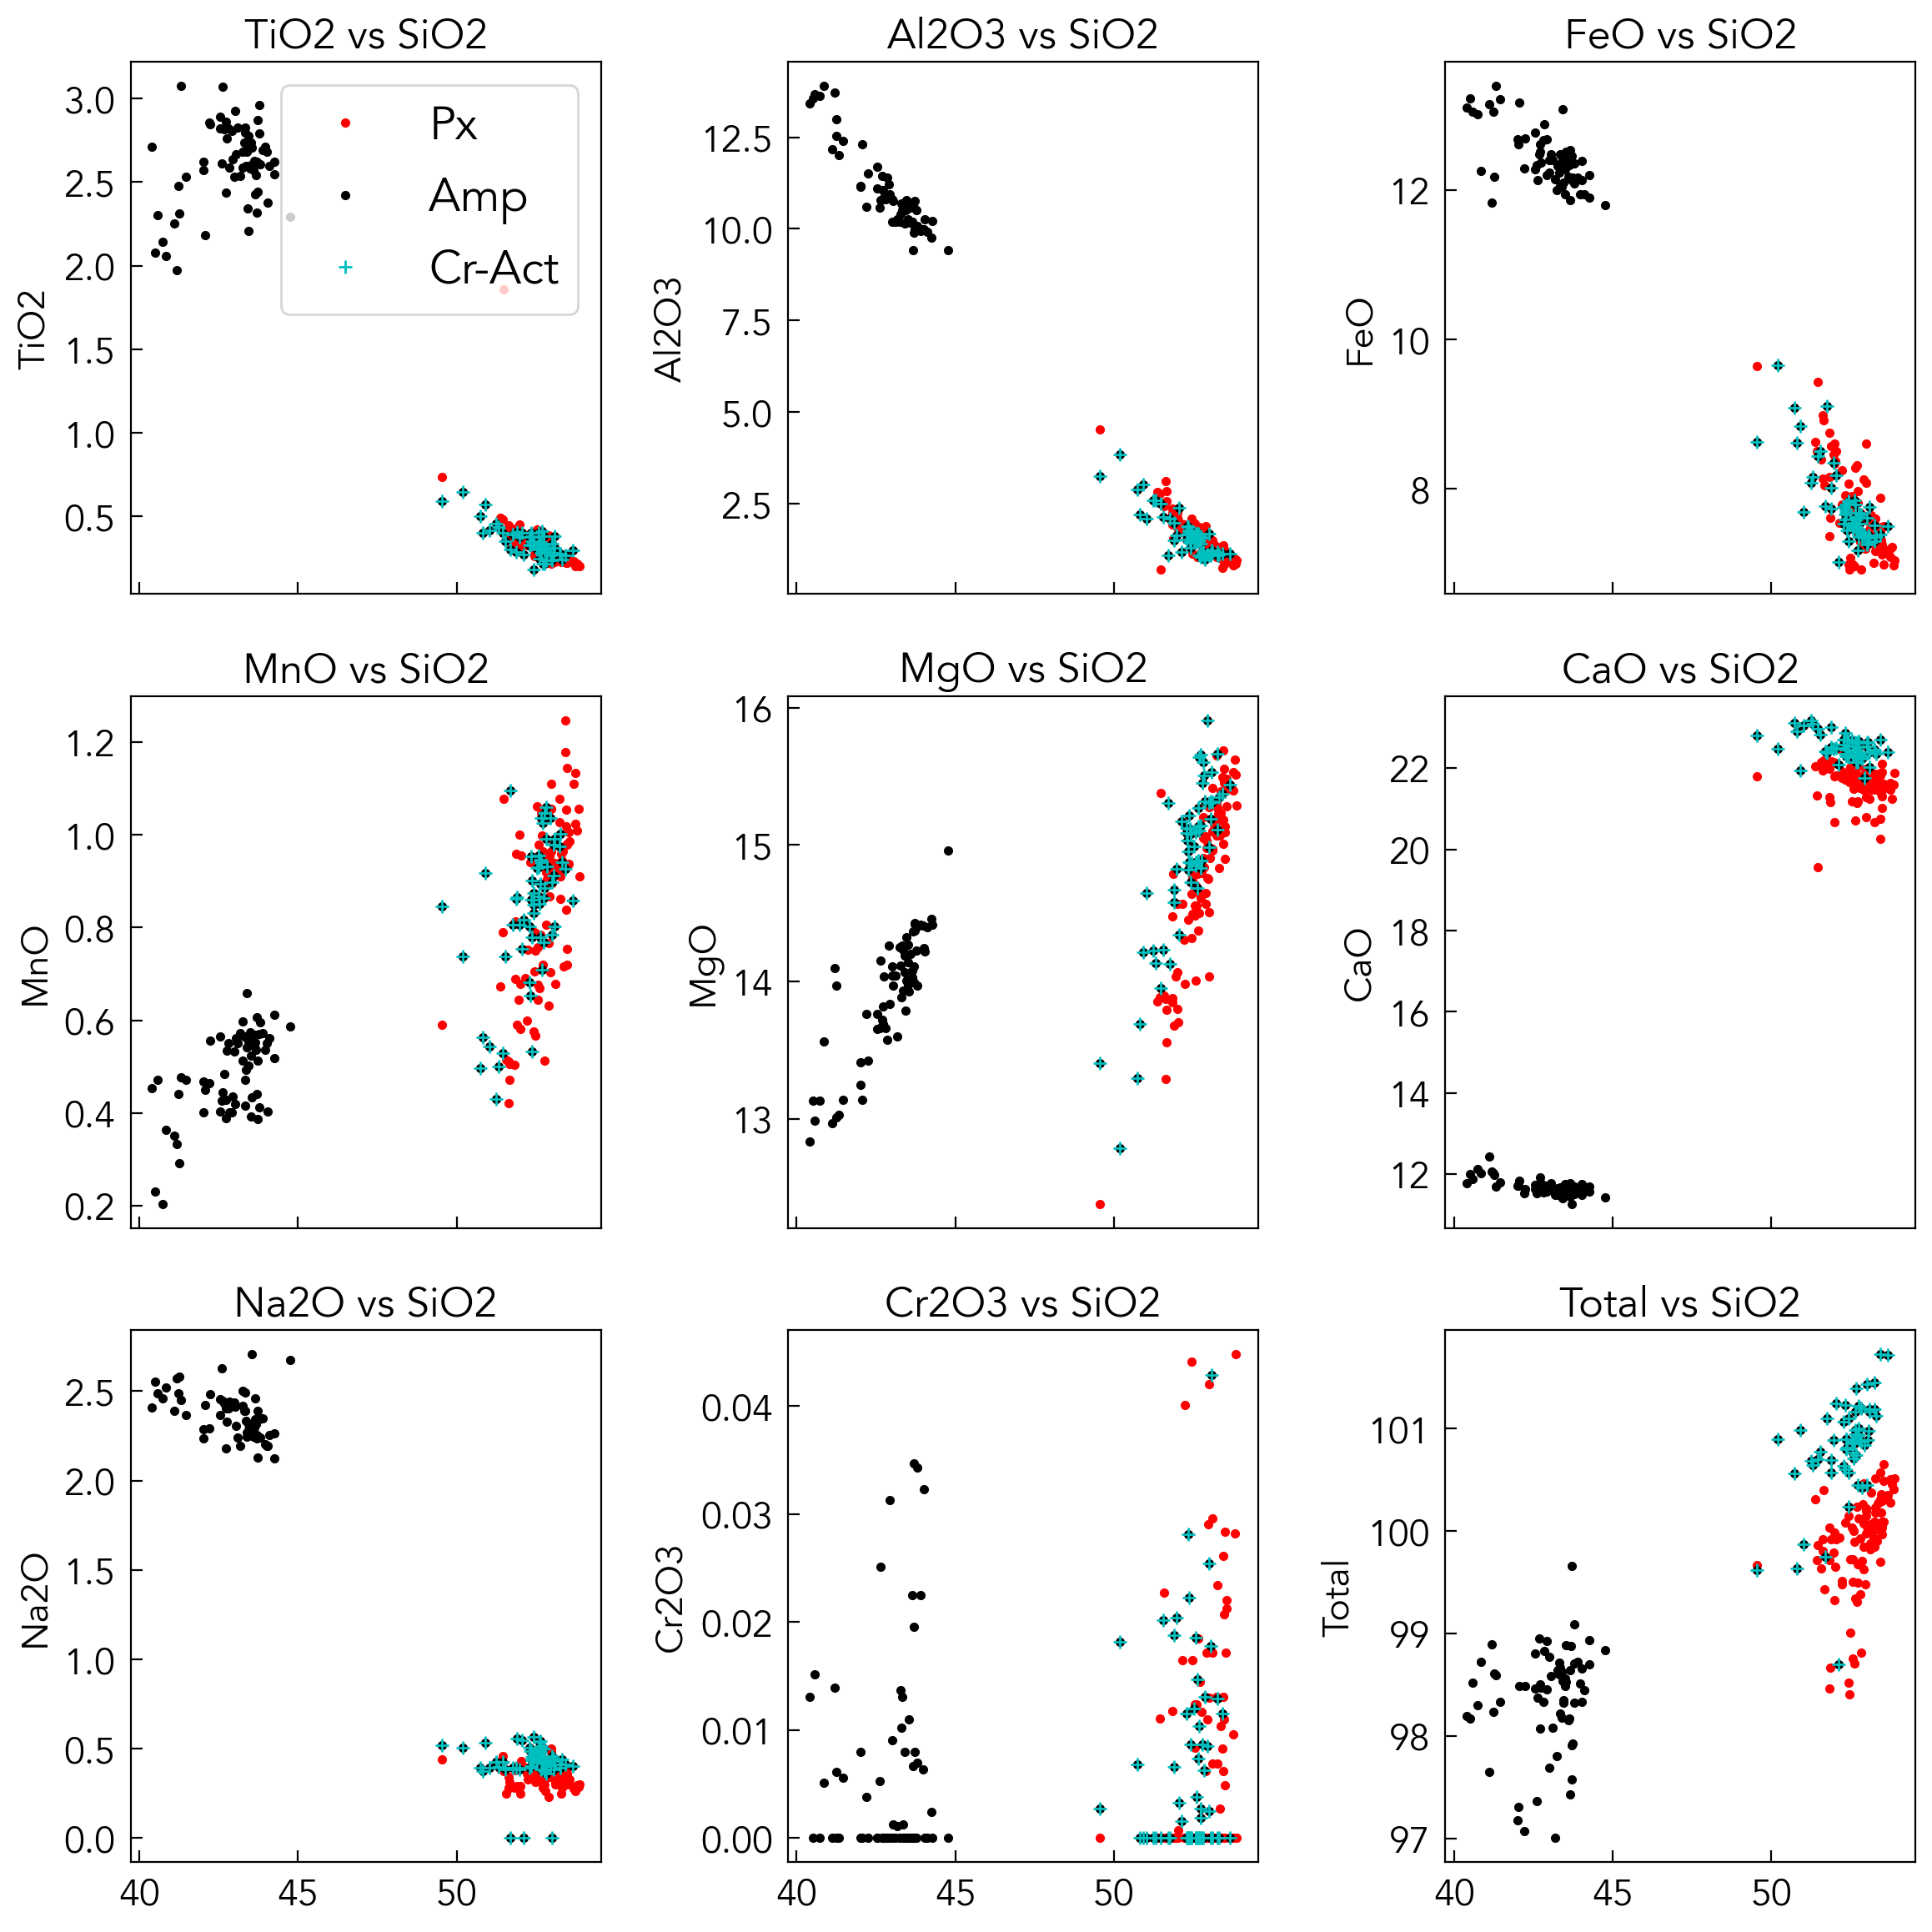

In [44]:
import matplotlib.pyplot as plt
import math

x = 'SiO2'

# ← Use the oxide list you defined earlier
oxides = [
    'TiO2', 'Al2O3', 'FeO', 'MnO',
    'MgO', 'CaO', 'Na2O', 
    'Cr2O3',  'Total' # modify to match your exact list
]

ncols = 3
nplots = len(oxides)
nrows = math.ceil(nplots / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4*nrows), sharex=True)
axes = axes.flatten()

Act = df_TC_Amp['MineralGroup'] == '(Cr-Actinolite)'

for i, y in enumerate(oxides):
    ax = axes[i]

    # Px
    ax.plot(df_TC_Px[x], df_TC_Px[y], '.r', label='Px')

    # Amp (all)
    ax.plot(df_TC_Amp[x], df_TC_Amp[y], '.k', label='Amp')

    # Cr-Actinolite highlight
    ax.plot(df_TC_Amp.loc[Act, x],
            df_TC_Amp.loc[Act, y],
            '+c', label='Cr-Act')

    ax.set_ylabel(y)
    ax.set_title(f'{y} vs SiO2')

# Remove unused axes
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

axes[0].legend()
plt.tight_layout()
plt.show()
fig.savefig('actinolites_or_pyroxenes.png')

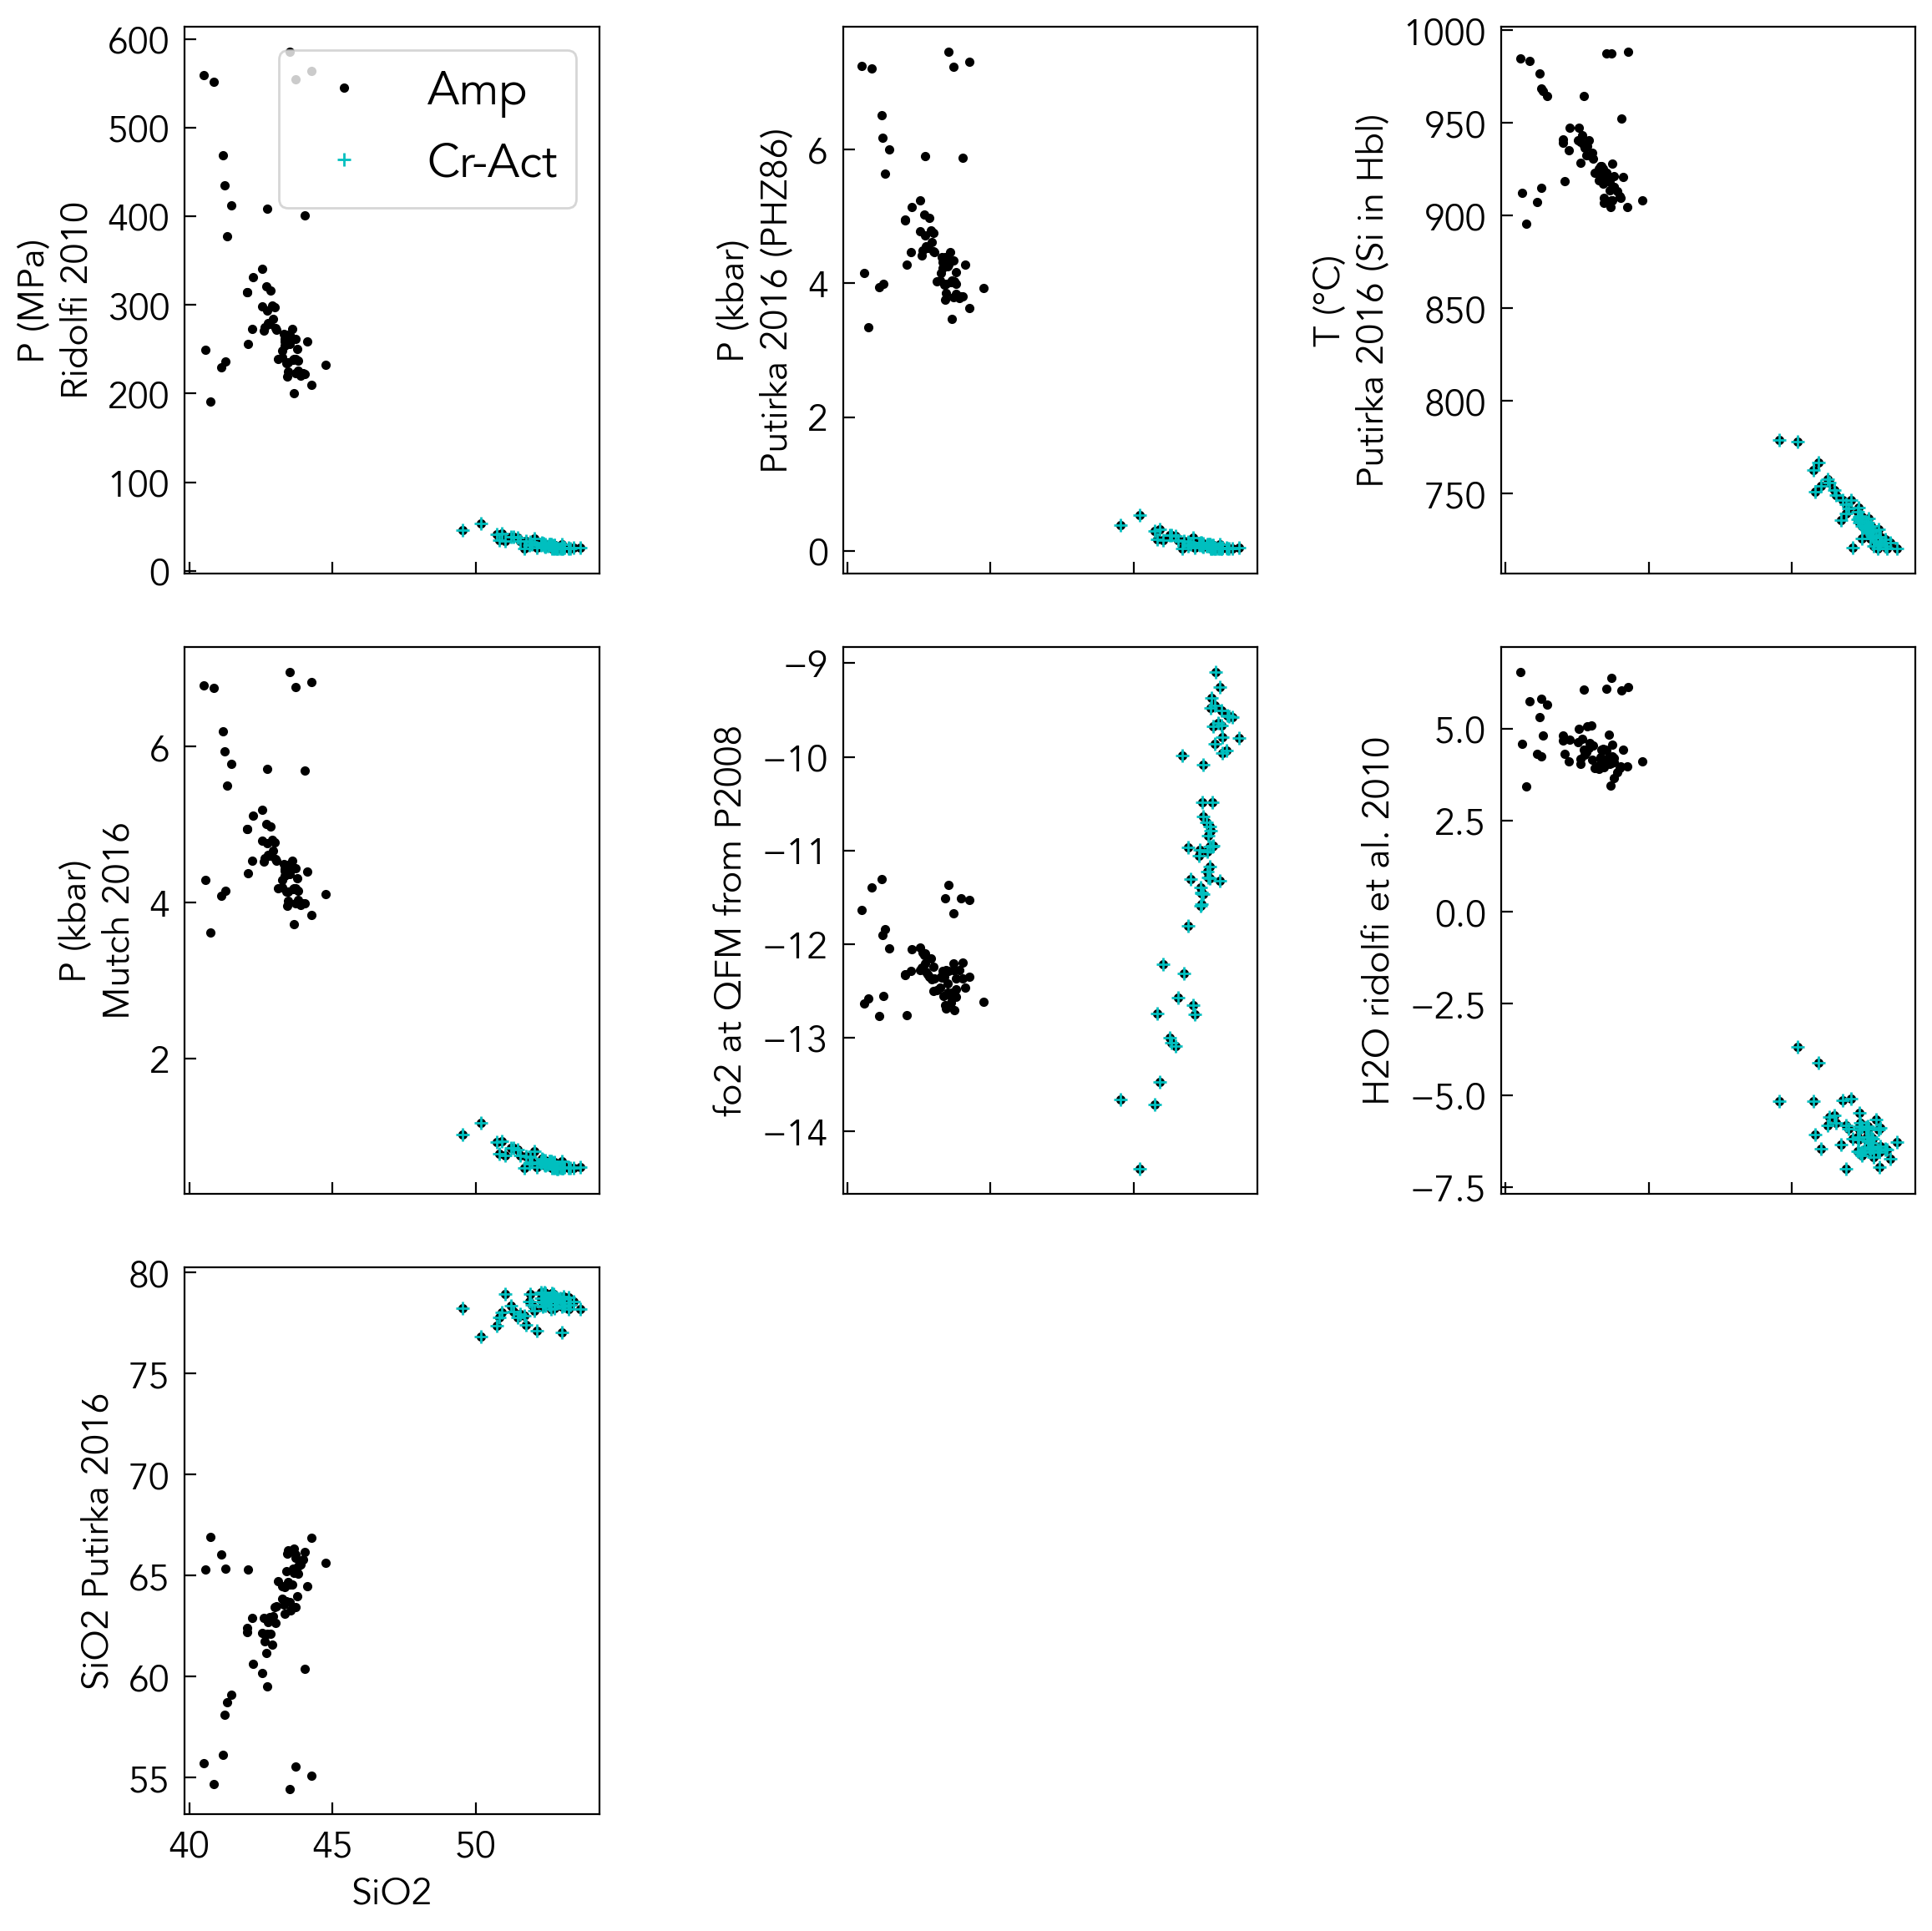

In [45]:
import matplotlib.pyplot as plt
import math

x = 'SiO2'

# Column names (used for pulling data)
oxides = [
    'PR10(MPa)a',
    'Put16a_PHZ86(kbar)a',
    '[TP16SiinHbl(oC)a',
    '[PM16(kbar)a]',
    '[QFM_P16(fO2)a',
    'H2OmeltR10(%)a',
    'SiO2(wt%)a-l]'
]

# 👇 Axis label key (edit freely)
oxide_labels = {
    'PR10(MPa)a': 'P (MPa)\nRidolfi 2010',
    'Put16a_PHZ86(kbar)a': 'P (kbar)\nPutirka 2016 (PHZ86)',
    '[TP16SiinHbl(oC)a': 'T (°C)\nPutirka 2016 (Si in Hbl)',
    '[PM16(kbar)a]': 'P (kbar)\nMutch 2016',
    '[QFM_P16(fO2)a': 'fo2 at QFM from P2008',
    'H2OmeltR10(%)a': 'H2O ridolfi et al. 2010',
    'SiO2(wt%)a-l]': 'SiO2 Putirka 2016'
}

ncols = 3
nplots = len(oxides)
nrows = math.ceil(nplots / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(12, 4*nrows), sharex=True)
axes = axes.flatten()

Act = df_TC_Amp['MineralGroup'] == '(Cr-Actinolite)'

for i, y in enumerate(oxides):
    ax = axes[i]

    # Amphibole
    ax.plot(df_TC_Amp[x], df_TC_Amp[y], '.k', label='Amp')

    # Cr-Actinolite highlight
    ax.plot(df_TC_Amp.loc[Act, x],
            df_TC_Amp.loc[Act, y],
            '+c', label='Cr-Act')

    # 👇 Use custom label instead of column name
    ax.set_ylabel(oxide_labels.get(y, y))
    #ax.set_title(f'{oxide_labels.get(y, y)} vs SiO₂')

# Remove unused axes
for j in range(i+1, len(axes)):
    fig.delaxes(axes[j])

axes[0].legend()
ax.set_xlabel('SiO2')
plt.tight_layout()
plt.show()

fig.savefig('Thermobarometry.png', dpi=300)